# Paper 06: U-Net: Convolutional Networks for Biomedical Image Segmentation
**Authors**: Olaf Ronneberger, Philipp Fischer, Thomas Brox (2015)

---

## 1. The Historical Breaking Point: The Spatial Localization Crisis
Classical ConvNets (AlexNet, VGG, ResNet) excel at image classification by compressing $(B, 3, H, W)$ inputs into a single category vector.
However, dense per-pixel prediction tasks (biomedical segmentation, object masking, generative diffusion models, robot trajectory diffusion) require outputting predictions with the **exact same spatial resolution** $(H, W)$ as the input image.

- **The Dilemma**: Pooling and downsampling operations capture deep, high-level semantic context ("WHAT is in the image"), but irrevocably destroy fine spatial coordinates ("WHERE the exact boundary is").
- **Simple Autoencoders Failed**: Upsampling directly from a low-dimensional bottleneck produced blurry, smeared boundaries because edge coordinates were discarded.

## 2. The First-Principles Solution: Multi-Scale Long Skip Connections
Ronneberger et al. invented a symmetric **U-shaped architecture**:
1. **Contracting Path (Encoder)**: Captures multi-scale contextual features via repeated convolutions and max-pooling.
2. **Expanding Path (Decoder)**: Recovers spatial resolution via upsampling (bilinear or transposed convolution).
3. **Long Skip Connections**: Concatenates high-resolution feature maps directly from the encoder into the decoder at each matching scale.

The decoder receives both **deep semantic abstractions** from the bottleneck and **pixel-precise edge localization** from the encoder skips!

In this notebook, you will test `DoubleConv`, `Down`, `Up`, and `UNet` implemented in `model.py`.

---
## Setup
`%autoreload 2` ensures any modifications in `model.py` are immediately refreshed.

In [17]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from model import DoubleConv, Down, Up, UNet
from core.optimizers import AdamW
import tests

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## Part 1: DoubleConv, Down, and Up Verification

We verify:
1. `DoubleConv`: Preserves spatial resolution $(H, W)$ while expanding channels.
2. `Down`: Halves spatial resolution via MaxPool2d and applies DoubleConv.
3. `Up`: Upsamples feature maps, handles spatial padding for odd dimensions, and concatenates encoder skip connections.

In [18]:
print("Testing DoubleConv Shape:")
tests.test_double_conv_shape(DoubleConv)

print("\nTesting Down Block Shape:")
tests.test_down_shape(Down)

print("\nTesting Up Block Concatenation & Spatial Padding:")
tests.test_up_concatenation_shape(Up)

Testing DoubleConv Shape:
  [PASS] DoubleConv correctly preserves spatial resolution (64x64)!

Testing Down Block Shape:
  [PASS] Down block halves spatial dimensions (64x64 -> 32x32)!

Testing Up Block Concatenation & Spatial Padding:
  [PASS] Up block correctly upsamples, concatenates skip connections, and handles padding!


True

---
## Part 2: Full Architecture & Segmentation Overfit Gate

We verify:
1. Exact spatial resolution preservation from input $(B, 3, 128, 128)$ to output mask $(B, 1, 128, 128)$.
2. Multi-class mask prediction $(B, 5, 128, 128)$.
3. **Single-Batch Overfit Gate**: Rapid convergence on a binary segmentation task.

In [19]:
print("Testing Full U-Net Spatial Preservation:")
tests.test_unet_full_resolution_preservation(UNet)

print("\nTesting Single-Batch Segmentation Overfit Gate:")
tests.test_unet_overfit_toy_mask(UNet)

Testing Full U-Net Spatial Preservation:
  [PASS] U-Net preserves exact spatial resolution: (B, 3, 128, 128) -> (B, 1, 128, 128)!
  [PASS] Multi-class U-Net output matches (B, 5, 128, 128)!

Testing Single-Batch Segmentation Overfit Gate:
  [PASS] Single-batch segmentation overfit passed (loss: 0.6413 -> 0.030540)!


True

---
## Part 3: The Power of Skip Connections: Sharp vs Blurry Boundaries

We train two networks on a synthetic biomedical segmentation target (a cell with a circular membrane):
1. **U-Net (With Skips)**: Combines encoder boundary details with deep context.
2. **Bottleneck Autoencoder (Without Skips)**: Compresses all information down to $4\times 4$ latent space without skip connections.

Notice how skip connections restore crisp, pixel-accurate boundaries!

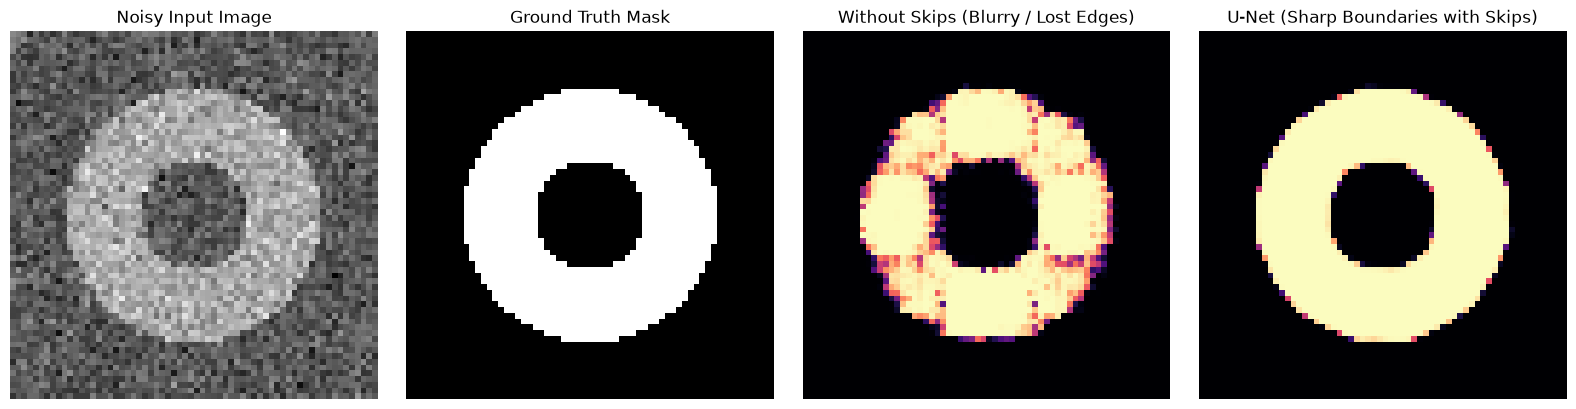

Final BCE Loss -> Without Skips: 0.0389 | U-Net: 0.0052


In [20]:
torch.manual_seed(42)
H, W = 64, 64

# 1. Create synthetic image and target circular mask
y_coords, x_coords = torch.meshgrid(torch.linspace(-1, 1, H), torch.linspace(-1, 1, W), indexing='ij')
radius = torch.sqrt(x_coords ** 2 + y_coords ** 2)
target_mask = ((radius > 0.3) & (radius < 0.7)).float().unsqueeze(0).unsqueeze(0)
input_img = target_mask + 0.3 * torch.randn(1, 1, H, W) # noisy observation

# 2. Naive Autoencoder WITHOUT skip connections
class NaiveAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(128, 256, 3, stride=2, padding=1), nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, stride=2, padding=1),
        )
    def forward(self, x):
        return self.decoder(self.encoder(x))

unet = UNet(in_channels=1, num_classes=1, bilinear=True)
naive_ae = NaiveAutoencoder()

criterion = nn.BCEWithLogitsLoss()
opt_u = AdamW(unet.parameters(), lr=0.01)
opt_ae = AdamW(naive_ae.parameters(), lr=0.01)

# Train both for 40 steps
for _ in range(40):
    opt_u.zero_grad()
    loss_u = criterion(unet(input_img), target_mask)
    loss_u.backward()
    opt_u.step()
    
    opt_ae.zero_grad()
    loss_ae = criterion(naive_ae(input_img), target_mask)
    loss_ae.backward()
    opt_ae.step()

with torch.no_grad():
    pred_u = torch.sigmoid(unet(input_img))[0, 0].cpu().numpy()
    pred_ae = torch.sigmoid(naive_ae(input_img))[0, 0].cpu().numpy()

# Plot the comparison
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(input_img[0, 0].numpy(), cmap='gray')
axes[0].set_title('Noisy Input Image')
axes[1].imshow(target_mask[0, 0].numpy(), cmap='gray')
axes[1].set_title('Ground Truth Mask')
axes[2].imshow(pred_ae, cmap='magma')
axes[2].set_title('Without Skips (Blurry / Lost Edges)')
axes[3].imshow(pred_u, cmap='magma')
axes[3].set_title('U-Net (Sharp Boundaries with Skips)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

print(f"Final BCE Loss -> Without Skips: {loss_ae.item():.4f} | U-Net: {loss_u.item():.4f}")